#1. Importación de librerias y carga del conjunto de datos público.
Para la cagra de los datos se utlilizó la librería de scikit learn para hacer su importación directamente sobre el programa con el fin de evitar complicaciones al momento de tratar con los mismos en la depuración y nombramiento de los nombres de cada categoría.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report


# O bien, se puede cargar directamente desde scikit-learn o un repositorio espejo verificado.
# Para fines prácticos de lectura directa con Pandas:
from sklearn.datasets import load_breast_cancer
import sklearn.datasets

#Lectura de datos con sklearn
sklearn.datasets.load_breast_cancer(as_frame=True)
data = load_breast_cancer(as_frame=True)
df = data.frame

# Asignación de nombres básicos a las columnas principales (ID, Diagnóstico y 30 características)
# Columna 0: ID, Columna 1: Diagnosis (M/B), Columnas 2-31: Características de los núcleos celulares.
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst pe

#2. Resumen estadístico
Resumen estadístico; muestra desviación estándar, mínimo, máxima, y sus cuartiles.

In [ ]:
# Resumen estadístico
print(df.describe())

       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.000000   
25%      

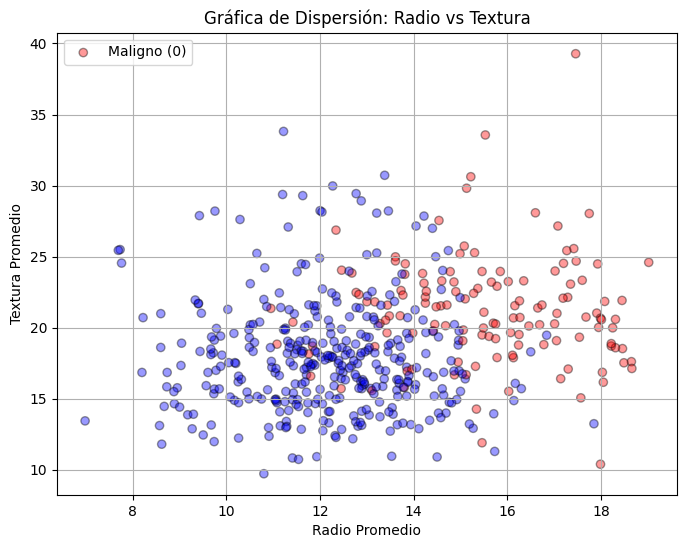

In [ ]:
#Desarrollo de la gráfica de dispersión
plt.figure(figsize=(8, 6))
colors = ['red' if target == 0 else 'blue' for target in df['target']]
plt.scatter(df['mean radius'], df['mean texture'], c=colors, alpha=0.4, edgecolors='k')
plt.xlabel('Radio Promedio')
plt.ylabel('Textura Promedio')
plt.title('Gráfica de Dispersión: Radio vs Textura')
plt.grid(True)
plt.legend(['Maligno (0)', 'Benigno (1)'])
plt.show()


#3. Limpieza y procesamineto de datos
Se buscan valores NaN en todas las columnas del dataset para realizar su depurado, sin embargo, se aprecia que ninguna de ellas posee valores nulos, por lo que no es necesario aplicar ninguna estrategia de limpieza a la lista.

In [ ]:
# Identificación de los valores NaN por columna
print('Valores NaN por columna ')
print(df.isnull().sum())
print("\n Valores nulos totales:", df.isnull().sum().sum())

Valores NaN por columna 
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

 Valores nulos totales: 0


#Tratamiento de valores atipicos.
Primero se definen los percentiles cuartilicos para poder definir los outliers y así dejar las muestras dentro del ancho del 50% central de los datos y así evitar que valores atípicos se cuelen en el entrenamiento del modelo.

Se define el dataframe nuevo con la media del área delimitada, se resetea el indice de los número para que hagan el conteo desde el 0 ordenadamente (ya que se eliminaron algunas filas en la delimitación de outliers) y se muestra el dataframe.

In [ ]:
Q1 = df['mean area'].quantile(0.25)
Q3 = df['mean area'].quantile(0.75)
IQR = Q3 - Q1
Upper_limit = Q3 + 1.5 * IQR
Lower_limit = Q1 - 1.5 * IQR
df_clean = df[(df['mean area'] <= Upper_limit) & (df['mean area'] >= Lower_limit)].reset_index(drop=True)
print("Muestras antes de limpiar:", len(df), "Muestras despues de limpiar:", len(df_clean))
df_clean.isnull().sum()
df_clean.describe()
df_clean.head()

Muestras antes de limpiar: 492 Muestras despues de limpiar: 483


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,0
1,11.42,20.38,77.58,386.1,0.1425,0.2839,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,0
2,12.45,15.70,82.57,477.1,0.1278,0.1700,0.15780,0.08089,0.2087,0.07613,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.1244,0
3,13.71,20.83,90.20,577.9,0.1189,0.1645,0.09366,0.05985,0.2196,0.07451,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.1151,0
4,13.00,21.82,87.50,519.8,0.1273,0.1932,0.18590,0.09353,0.2350,0.07389,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.1072,0


##4. Entrenamiento y evaluación del árbol de decisión


--- Evaluación del Modelo ---
Exactitud Global (Accuracy): 0.9587

Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        31
           1       0.97      0.98      0.97        90

    accuracy                           0.96       121
   macro avg       0.95      0.94      0.95       121
weighted avg       0.96      0.96      0.96       121



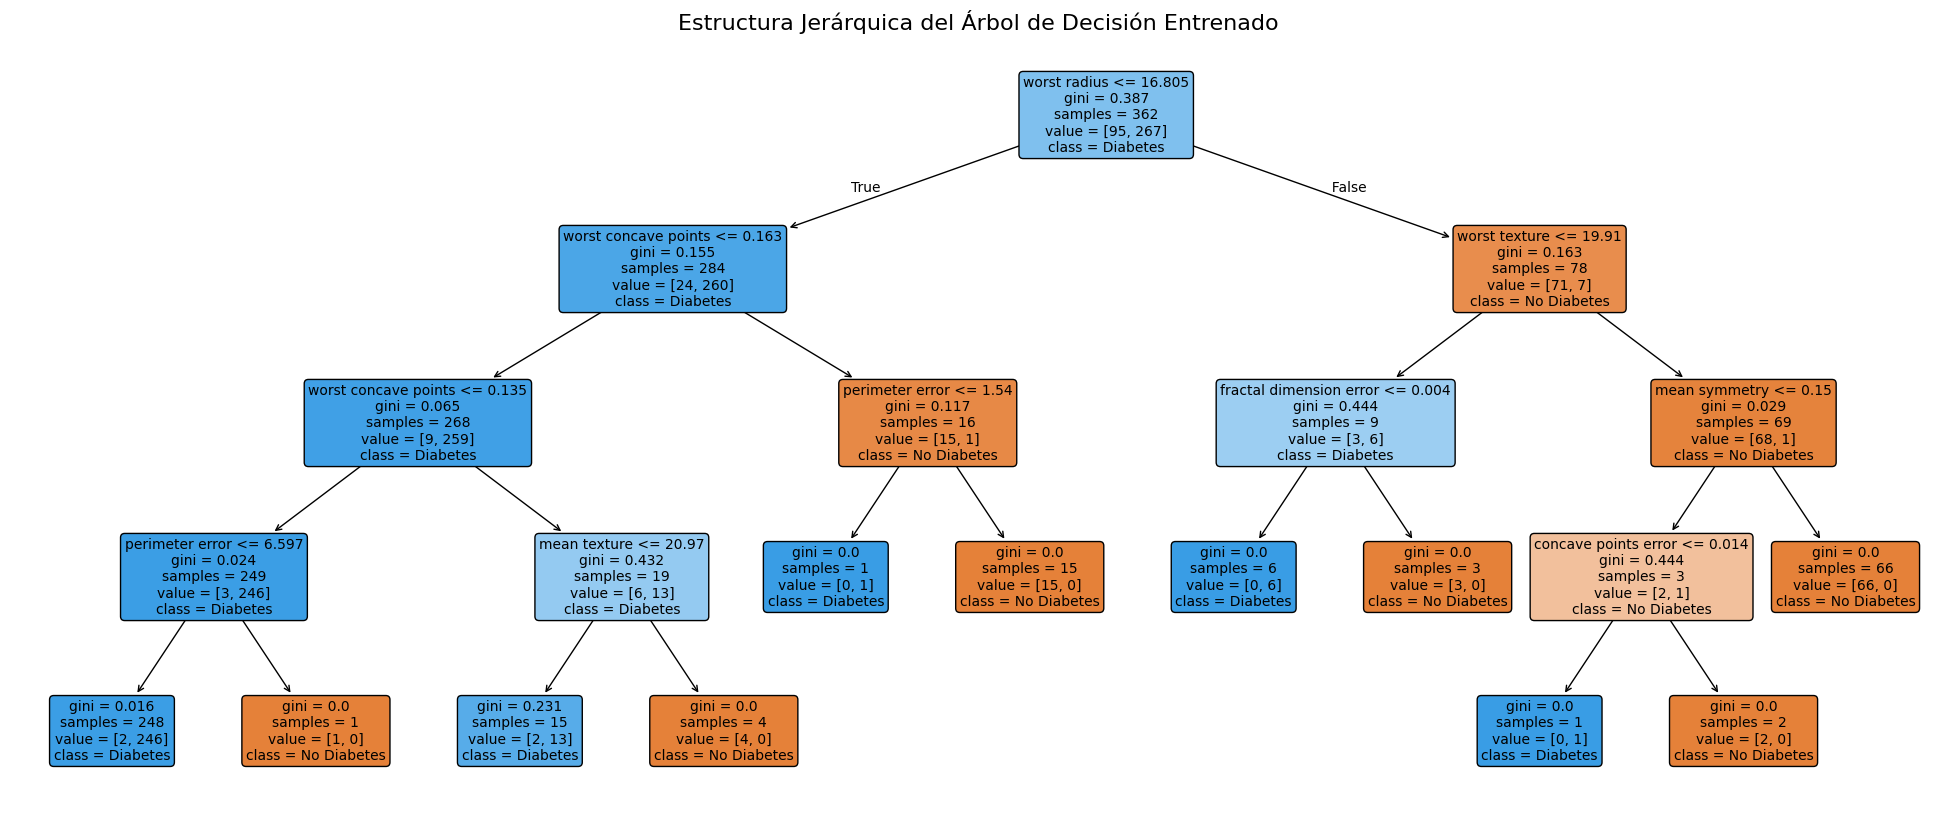

In [ ]:
# Separación de características independientes (X) y variable de etiquetas objetivo (y)
# Se utiliza el dataframe corregido: df_clean
X = df_clean.drop(columns=['target'])
y = df_clean['target']

# Partición del conjunto (75% Entrenamiento, 25% Prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Inicialización y entrenamiento del modelo
modelo_arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_arbol.fit(X_train, y_train)

# Generación de predicciones y cálculo de métricas de desempeño
y_pred = modelo_arbol.predict(X_test)
exactitud = accuracy_score(y_test, y_pred)

print("--- Evaluación del Modelo ---")
print(f"Exactitud Global (Accuracy): {exactitud:.4f}")
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred))

# Visualización de la Estructura Jerárquica del Árbol
plt.figure(figsize=(25, 10))
plot_tree(
    modelo_arbol,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura Jerárquica del Árbol de Decisión Entrenado", fontsize=16)
plt.show()